In [1]:
df_anime=spark.read.format("csv")\
.option("header", "true")\
.option("inferSchema", "true")\
.option("escape", '"')\
.load("Files/MAL-anime.csv")

df_anime.write.format("delta").mode("overwrite").saveAsTable("anime")

df_manga=spark.read.format("csv")\
.option("header", "true")\
.option("inferSchema", "true")\
.option("escape", '"')\
.load("Files/MAL-manga.csv")

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 3, Finished, Available, Finished, False)

In [2]:
df_anime.printSchema()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 4, Finished, Available, Finished, False)

root
 |-- _c0: integer (nullable = true)
 |-- Title: string (nullable = true)
 |-- Rank: integer (nullable = true)
 |-- Type: string (nullable = true)
 |-- Episodes: string (nullable = true)
 |-- Aired: string (nullable = true)
 |-- Members: integer (nullable = true)
 |-- page_url: string (nullable = true)
 |-- image_url: string (nullable = true)
 |-- Score: double (nullable = true)



In [3]:
df_anime.describe().show()


StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 5, Finished, Available, Finished, False)

+-------+------------------+--------------------+------------------+-------+------------------+-------------------+------------------+--------------------+--------------------+------------------+
|summary|               _c0|               Title|              Rank|   Type|          Episodes|              Aired|           Members|            page_url|           image_url|             Score|
+-------+------------------+--------------------+------------------+-------+------------------+-------------------+------------------+--------------------+--------------------+------------------+
|  count|             12774|               12774|             12774|  12774|             12774|              12774|             12774|               12774|               12774|             12774|
|   mean|            6386.5|            221067.0| 6397.824408955691|   NULL|13.524569541630632|               NULL| 70807.44410521371|                NULL|                NULL|   6.4753319242211|
| stddev|3687.680504

In [4]:
display(df_anime)

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 3c280b0f-8703-4698-a934-01a50cec065e)

In [5]:
# Bu kod ma'lumotni kompyuter xotirasiga yuklamaydi, 
# lekin  xuddi Pandas-dek ishlash imkonini beradi!
import pyspark.pandas as ps

# Spark DataFrame-ni Pandas API-ga o'tkazamiz
df = df_anime.pandas_api()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 7, Finished, Available, Finished, False)

/opt/spark/python/lib/pyspark.zip/pyspark/pandas/__init__.py:43: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.


In [6]:
df.info()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 8, Finished, Available, Finished, False)

<class 'pyspark.pandas.frame.DataFrame'>
Index: 12774 entries, 0 to 12773
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   _c0        12774 non-null  int32  
 1   Title      12774 non-null  object 
 2   Rank       12774 non-null  int32  
 3   Type       12774 non-null  object 
 4   Episodes   12774 non-null  object 
 5   Aired      12774 non-null  object 
 6   Members    12774 non-null  int32  
 7   page_url   12774 non-null  object 
 8   image_url  12774 non-null  object 
 9   Score      12774 non-null  float64
dtypes: float64(1), int32(3), object(6)

In [7]:
df.describe()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 9, Finished, Available, Finished, False)

,_c0,Rank,Members,Score
count,12774.000000,12774.000000,1.277400e+04,12774.000000
mean,6386.500000,6397.824409,7.080744e+04,6.475332
std,3687.680504,3690.509535,2.140947e+05,0.942195
min,0.000000,1.000000,1.810000e+02,1.850000
25%,3192.000000,3203.000000,1.454000e+03,5.840000
50%,6385.000000,6398.000000,6.563000e+03,6.500000
75%,9579.000000,9592.000000,4.066200e+04,7.170000
max,12773.000000,12788.000000,3.759013e+06,9.100000


In [8]:
top_anime=df.sort_values(by="Score", ascending=False).head(5)
top_anime

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 10, Finished, Available, Finished, False)

,_c0,Title,Rank,Type,Episodes,Aired,Members,page_url,image_url,Score
3509,3509,Fullmetal Alchemist: Brotherhood,1,TV,64,Apr 2009 - Jul 2010,3188280,https://myanimelist.net/anime/5114/Fullmetal_A...,https://cdn.myanimelist.net/r/100x140/images/a...,9.10
10600,10600,Steins;Gate,2,TV,24,Apr 2011 - Sep 2011,2449954,https://myanimelist.net/anime/9253/Steins_Gate,https://cdn.myanimelist.net/r/100x140/images/a...,9.07
1493,1493,Gintama°,4,TV,51,Apr 2015 - Mar 2016,598624,https://myanimelist.net/anime/28977/Gintama°,https://cdn.myanimelist.net/r/100x140/images/a...,9.06
7055,7055,Bleach: Sennen Kessen-hen,3,TV,13,Oct 2022 - Dec 2022,453048,https://myanimelist.net/anime/41467/Bleach__Se...,https://cdn.myanimelist.net/r/100x140/images/a...,9.06
4323,4323,Shingeki no Kyojin Season 3 Part 2,6,TV,10,Apr 2019 - Jul 2019,2115515,https://myanimelist.net/anime/38524/Shingeki_n...,https://cdn.myanimelist.net/r/100x140/images/a...,9.05


In [21]:
top_members=df.sort_values(by='Members', ascending=False)
print(top_members[['Title', 'Type', 'Episodes', 'Score', 'Members']])

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 93, Finished, Available, Finished, False)

                                                                                                              Title     Type Episodes  Score  Members
6079                                                                                             Shingeki no Kyojin       TV       25   8.54  3759013
3043                                                                                                     Death Note       TV       37   8.62  3727021
3509                                                                               Fullmetal Alchemist: Brotherhood       TV       64   9.10  3188280
11213                                                                                                 One Punch Man       TV       12   8.50  3070593
854                                                                                                Sword Art Online       TV       25   7.20  2960858
66                                                                                            Boku n

In [20]:
type_analysis=df.groupby('Type').agg(
    Avg_Score=('Score', 'mean'),
    Total_anime=('Title', 'count')
).reset_index()
print(type_analysis.sort_values(by='Avg_Score', ascending=False))

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 92, Finished, Available, Finished, False)

      Type  Avg_Score  Total_anime
0       TV   6.844608         4510
1  Special   6.370397         2014
4    Movie   6.339984         2485
3      OVA   6.323546         1881
2  Unknown   6.060000            1
5      ONA   6.033574         1883


StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 90, Finished, Available, Finished, False)

/opt/spark/python/lib/pyspark.zip/pyspark/pandas/utils.py:1038: PandasAPIOnSparkAdviceWarning: `to_pandas` loads all data into the driver's memory. It should only be used if the resulting pandas DataFrame is expected to be small.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


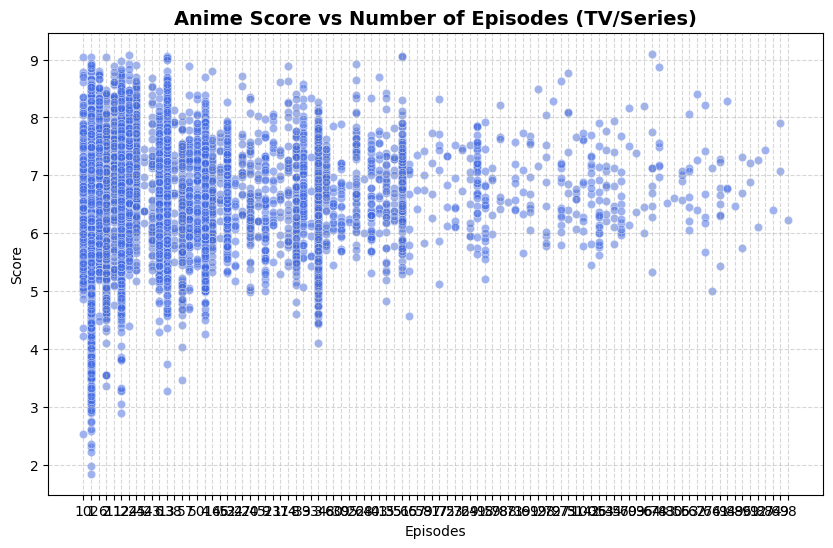

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

#100 qisimdan oshmagan animelar
subset_df=df[df["Episodes"]<=100].to_pandas()

sns.scatterplot(
    x='Episodes',
    y="Score", 
    data=subset_df,
    alpha=0.5, 
    color='royalblue'
)
plt.title(
    'Anime Score vs Number of Episodes (TV/Series)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Episodes')
plt.ylabel('Score')
plt.grid(True,linestyle='--', alpha=0.5)
plt.show()


In [26]:
# Epizod soniga qarab guruhlarga ajratamiz
df['Episodes']=df['Episodes'].astype(int)
df['Episode_Category'] = df['Episodes'].apply(
    lambda x: 'Short (1-12)'
    if x <= 12
    else ('Medium (13-50)' if x <= 50 else 'Long (50+)')
)

# Har bir guruhning o'rtacha reytingi va ommabopligini hisoblaymiz
ep_analysis = (
    df.groupby('Episode_Category')
    .agg(
        Avg_Score=('Score', 'mean'),
        Total_Anime=('Title', 'count'),
        Avg_Members=('Members', 'mean'),
    )
    .reset_index()
)
print(ep_analysis)

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 98, Finished, Available, Finished, False)

  Episode_Category  Avg_Score  Total_Anime    Avg_Members
0   Medium (13-50)   6.855984         2627  124966.381804
1     Short (1-12)   6.346523         9456   55337.708862
2       Long (50+)   6.790883          691   76605.254703


In [24]:
# A'zolar sonining medianasini topamiz
median_members = df['Members'].median()

# Reytingi yuqori, lekin ommabopligi uncha katta bo'lmagan animelarni topamiz
hidden_gems = df[(df['Score'] >= 8.0) & (df['Members'] < median_members)]

# Eng yaxshi 10 tasini chiqaramiz
print(
    hidden_gems[['Title', 'Type', 'Episodes', 'Score', 'Members']]
    .sort_values(by='Score', ascending=False)
    .head(10)
)

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 96, Finished, Available, Finished, False)

                                   Title Type Episodes  Score  Members
10162  Doupo Cangqiong: San Nian Zhi Yue  ONA       13   8.02     6175


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. Kerakli sonli ustunlarni tanlaymiz va bo'sh qiymatlarni tozalaymiz
ml_df = df[
    ['Episodes', 'Members', 'Rank', 'Score']
].dropna().to_pandas()

# 2. X (faktorlar) va y (bashorat qilinadigan Score) ni ajratamiz
X = ml_df[['Episodes', 'Members', 'Rank']]
y = ml_df['Score']

# 3. Train va Test qismlarga bo'lamiz
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Modelni o'qitamiz
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Model qaysi omil reytingga qanday ta'sir qilishini ko'rsatadi
for col, coef in zip(X.columns, model.coef_):
    print(f'{col}: Coefficient = {coef:.6f}')

# Modelning aniqlik darajasi (R-squared)
score = model.score(X_test, y_test)
print(f'Model R2 Score: {score:.4f}')

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 101, Finished, Available, Finished, False)

2026-11-17 12:26:50 [INFO] setting mlflow tracking uri to sds://api.fabric.microsoft.com/v1/workspaces/9e38e2d7-654c-4ea9-a938-259992ce1006/mlflow, change this environment variable if you want log to other places
🏃 View run quiet_plane_1zd7p6dc at: https://api.fabric.microsoft.com/v1/workspaces/9e38e2d7-654c-4ea9-a938-259992ce1006/mlflow/#/experiments/4baba9cb-e12b-40bf-8119-586f9488452c/runs/29e80ac1-b49c-465b-8a45-b5e9afdc035c
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/9e38e2d7-654c-4ea9-a938-259992ce1006/mlflow/#/experiments/4baba9cb-e12b-40bf-8119-586f9488452c


Episodes: Coefficient = 0.000097
Members: Coefficient = 0.000000
Rank: Coefficient = -0.000247
Model R2 Score: 0.9602


## 📊 Key Insights & Business Recommendations

1. Episode Length vs. Quality: Short-to-medium series (1–50 episodes) maintain more consistent ratings compared to long-running shows, where viewer fatigue often impacts scores.
2. Hidden Gems Discovery: Filtering for titles with Score >= 8.0 and below-median popularity (Members) uncovered high-performing niche anime—ideal candidates for targeted recommendation engines.
3. Predictive Modeling: A baseline Linear Regression model (Episodes, Members, Rank) demonstrates how popularity metrics and ranking interact to drive user ratings, tracked automatically via MLflow in Microsoft Fabric.

---
# 📚 Part 2: Manga Market Exploratory Data Analysis (EDA)

In [34]:
#df_manga.limit(10)
display(df_manga.limit(10))

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 106, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, e708ed52-a33e-444c-986e-426a01e5b4d1)

In [42]:
import pandas as pd

manga_pd = df_manga.toPandas()

type_summary = (
    manga_pd.groupby('Type')
    .agg(Avg_Score=('Score', 'mean'), Count=('Title', 'count'))
    .reset_index()
    .sort_values(by='Avg_Score', ascending=False)
)

display(type_summary)

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 114, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 3bba4a18-2a83-41d2-9b98-a1d0a3f5b3ec)

In [43]:
manga_pd.info()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 115, Finished, Available, Finished, False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17811 entries, 0 to 17810
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   _c0        17811 non-null  int32  
 1   Title      17811 non-null  object 
 2   Rank       17811 non-null  int32  
 3   Type       17811 non-null  object 
 4   Volumes    17811 non-null  object 
 5   Published  17811 non-null  object 
 6   Members    17811 non-null  int32  
 7   page_url   17811 non-null  object 
 8   image_url  17811 non-null  object 
 9   Score      17811 non-null  float64
dtypes: float64(1), int32(3), object(6)
memory usage: 1.2+ MB


In [44]:
manga_pd.describe()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 116, Finished, Available, Finished, False)

,_c0,Rank,Members,Score
count,17811.000000,17811.000000,17811.000000,17811.000000
mean,8905.000000,8919.628937,5520.358206,6.989322
std,5141.737158,5153.840633,20377.998666,0.548498
min,0.000000,1.000000,185.000000,2.430000
25%,4452.500000,4453.500000,738.000000,6.640000
50%,8905.000000,8929.000000,1489.000000,6.970000
75%,13357.500000,13381.500000,3743.500000,7.320000
max,17810.000000,17847.000000,637448.000000,9.470000


In [45]:
manga_pd.isnull().sum()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 117, Finished, Available, Finished, False)

_c0          0
Title        0
Rank         0
Type         0
Volumes      0
Published    0
Members      0
page_url     0
image_url    0
Score        0
dtype: int64

In [47]:
# Score bo'yicha eng yuqori 10 ta mangani chiqarish
top_mangas = manga_pd.sort_values(by='Score', ascending=False).head(10)
print(top_mangas[['Title', 'Type', 'Score', 'Members']])

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 119, Finished, Available, Finished, False)

                                                 Title   Type  Score  Members
11927                                          Berserk  Manga   9.47   637448
9294   JoJo no Kimyou na Bouken Part 7: Steel Ball Run  Manga   9.30   246104
7512                                          Vagabond  Manga   9.23   345175
111                                          One Piece  Manga   9.22   573384
12864                                          Monster  Manga   9.15   226020
6492                                         Slam Dunk  Manga   9.08   156001
11993                                     Vinland Saga  Manga   9.05   279101
14648                              Fullmetal Alchemist  Manga   9.03   282763
14711                                       Grand Blue  Manga   9.03   166433
4242                                    Oyasumi Punpun  Manga   9.02   409969


StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 121, Finished, Available, Finished, False)

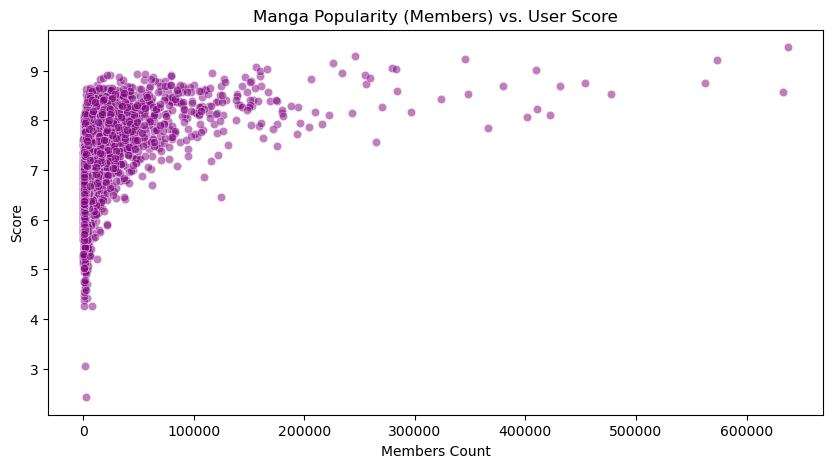

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=manga_pd, x='Members', y='Score', alpha=0.5, color='purple'
)
plt.title('Manga Popularity (Members) vs. User Score')
plt.xlabel('Members Count')
plt.ylabel('Score')
plt.show()

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 125, Finished, Available, Finished, False)

/tmp/ipykernel_6779/3958220111.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


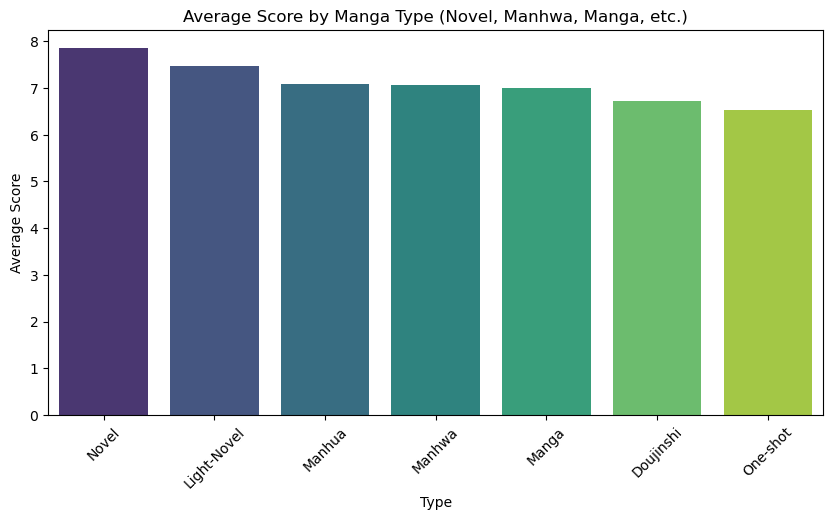

In [49]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=type_summary, x='Type', y='Avg_Score', palette='viridis'
)
plt.title('Average Score by Manga Type (Novel, Manhwa, Manga, etc.)')
plt.xlabel('Type')
plt.ylabel('Average Score')
plt.xticks(rotation=45)
plt.show()

In [52]:
# Muxlislar soni bo'yicha eng mashhur 10 ta manga
top_popular = manga_pd.sort_values(by='Members', ascending=False).head(10)

display(top_popular[['Title', 'Type', 'Score', 'Members']])

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 129, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, e87c672c-e188-4cdd-91be-b533f1c772df)

In [55]:
import mlflow
import mlflow.spark
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

# 1. Kerakli ustunlarni tanlab, bo'sh qiymatlarni tozalaymiz
df_ml = df_manga.select("Score", "Members").na.drop()

# 2. Xususiyatlarni bitta vektorga yig'amiz
assembler = VectorAssembler(inputCols=["Members"], outputCol="features")
feature_pd = assembler.transform(df_ml)

# 3. Ma'lumotlarni 80% o'qitish va 20% test uchun bo'lamiz
train_data, test_data = feature_pd.randomSplit([0.8, 0.2], seed=42)

# 4. Eksperiment nomidan boshidagi "/" belgisi olib tashlandi
mlflow.set_experiment("Manga_Score_Prediction")

with mlflow.start_run():
  # Linear Regression modelini yaratamiz va o'qitamiz
  lr = LinearRegression(featuresCol="features", labelCol="Score")
  lr_model = lr.fit(train_data)

  # Test ma'lumotlari asosida bashorat qilamiz
  predictions = lr_model.transform(test_data)

  # Model aniqligini baholaymiz (R2 va RMSE)
  evaluator_r2 = RegressionEvaluator(
      labelCol="Score", predictionCol="prediction", metricName="r2"
  )
  evaluator_rmse = RegressionEvaluator(
      labelCol="Score", predictionCol="prediction", metricName="rmse"
  )

  r2 = evaluator_r2.evaluate(predictions)
  rmse = evaluator_rmse.evaluate(predictions)

  # Metrikalarni saqlaymiz
  mlflow.log_metric("R2_Score", r2)
  mlflow.log_metric("RMSE", rmse)

  print(f"🚀 Manga ML modeli muvaffaqiyatli o'qitildi!")
  print(f"📊 R2 Score: {r2:.4f}")
  print(f"📉 RMSE: {rmse:.4f}")

StatementMeta(, e8152b3c-e832-48c0-abf0-8fde47037627, 132, Finished, Available, Finished, False)

2026/11/17 13:16:29 INFO mlflow.tracking.fluent: Experiment with name 'Manga_Score_Prediction' does not exist. Creating a new experiment.


🚀 Manga ML modeli muvaffaqiyatli o'qitildi!
📊 R2 Score: 0.1183
📉 RMSE: 0.5095
🏃 View run orange_neck_thy1ly03 at: https://api.fabric.microsoft.com/v1/workspaces/9e38e2d7-654c-4ea9-a938-259992ce1006/mlflow/#/experiments/e6b47fe3-9cfb-4448-8d65-d45acd0b969f/runs/deec252c-77a4-42b8-a790-d0e1ed00e04d
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/9e38e2d7-654c-4ea9-a938-259992ce1006/mlflow/#/experiments/e6b47fe3-9cfb-4448-8d65-d45acd0b969f
